# Test ccFBA_mr
ccFBA with multi-functional enzymes (python version of `cfba_moment_mr` in sybilccFBA): a gene catalyzing more than one reaction gets one concentration variable per reaction, and their sum is bounded by the gene concentration.

Same settings as `test_moment.ipynb`: iAF1260, RHS=0.27, medval=3600*22.6.

In [1]:
import os
#os.chdir(os.path.expanduser("ccFBApy"))
import ccfbapy as ccfba

In [2]:
import cobra
modelorg = cobra.io.read_sbml_model('models\\iAF1260.xml')

In [3]:
import pandas as pd
mw=pd.read_csv(r"data\ecoli_mw.csv")
kcat=pd.read_csv(r"data\ecoli_kcat.csv")

Res=ccfba.ccFBA_mr(modelorg,kcat,MW=mw,verboseMode=1,RHS=0.27,medval=3600*22.6)
print("Done...")

Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
Done...


In [4]:
print(Res['obj'],Res['status'])

0.24715053202832254 optimal


In [5]:
CSList=['EX_glc__D_e', 'EX_glyc_e', 'EX_ac_e', 'EX_fru_e', 'EX_pyr_e', 'EX_gal_e', 'EX_lac__L_e', 'EX_malt_e', 'EX_mal__L_e', 'EX_fum_e', 'EX_xyl__D_e', 'EX_man_e', 'EX_tre_e', 'EX_mnl_e', 'EX_g6p_e', 'EX_succ_e', 'EX_gam_e', 'EX_sbt__D_e', 'EX_glcn_e', 'EX_rib__D_e', 'EX_gsn_e', 'EX_ala__L_e', 'EX_akg_e', 'EX_acgam_e']
msrd=[0.66,0.47,0.29,0.54,0.41,0.24,0.41,0.52,0.55,0.47,0.51,0.35,0.48,0.61,0.78,0.50,0.40,0.48,0.68,0.41,0.37,0.24,0.24,0.61]
CA=[6,3,2,6,3,6,3,12,4,4,5,6,12,6,6,4,6,6,6,5,10,3,5,8]

In [6]:
for rid in CSList:
    modelorg.reactions.get_by_id(rid).lower_bound=0
    modelorg.reactions.get_by_id(rid).upper_bound=0
    #cL.append(rid[2:-3])
modelorg.reactions.get_by_id('EX_o2_e').lower_bound=-1000.0
modelorg.reactions.get_by_id('ATPM').lower_bound=0
modelorg.reactions.get_by_id('ATPM').upper_bound=0

In [7]:
modelR=modelorg.copy()

## Growth on 24 carbon sources

In [8]:
allRes=[]
bmv=[]
uptake=[]   # actual uptake of the carbon source (mmol/gDW/h) = -flux of its exchange reaction
for cs in range(24):
#for cs in [1]:    
    print(CSList[cs])
    model=modelR.copy()
    model.reactions.get_by_id(CSList[cs]).lower_bound=-1000.0
    Res=ccfba.ccFBA_mr(model,kcat,MW=mw,verboseMode=1,RHS=0.27,medval=3600*22.6)
    bmv.append(Res['obj'])
    uptake.append(-Res['rxnFlx'][CSList[cs]])
    print(Res['obj'],Res['status'],'uptake:',uptake[-1])
    del model
    del Res

EX_glc__D_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.2595836486848898 optimal uptake: 8.663579014124508
EX_glyc_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.27089694336905135 optimal uptake: 11.991682722265873
EX_ac_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.19949574878550774 optimal uptake: 9.83154003430193
EX_fru_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.2565636159196529 optimal uptake: 3.01601712595462
EX_pyr_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.22837551647564203 optimal uptake: 7.450438350560342
EX_gal_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.2552353356919018 optimal uptake: 3.0553326200576607
EX_lac__L_e
Preparing LP ...
Adding variables...
Adding constraints...
Solving LP ...
0.2298762715658182 optimal uptake: 7.3191038268473445
EX_malt_e
Preparing LP ...
Adding vari

In [9]:
print(bmv)

[0.2595836486848898, 0.27089694336905135, 0.19949574878550774, 0.2565636159196529, 0.22837551647564203, 0.2552353356919018, 0.2298762715658182, 0.25678937443447825, 0.233579133810491, 0.233324567482037, 0.2542661243969182, 0.2560357918147755, 0.2612162511314378, 0.2555832406715791, 0.2801797477231362, 0.23860603705635183, 0.2579010852619186, 0.2593859954481947, 0.2597680000853546, 0.23720813506951663, 0.28809865202728163, 0.23115348594547397, 0.24966028545120744, 0.2525162896523214]


In [10]:
from scipy.stats import pearsonr
corr, _ = pearsonr(bmv, msrd)
print(corr)

0.3983321723507156


In [11]:
# Measured vs predicted growth and the actual carbon source uptake of each simulation
# uptake: mmol/gDW/h, C_uptake: C-mmol/gDW/h (uptake * number of carbon atoms, CA)
resDF=pd.DataFrame({'carbon_source':CSList,'C_atoms':CA,'measured_growth':msrd,
                    'predicted_growth':bmv,'uptake':uptake})
resDF['C_uptake']=resDF['uptake']*resDF['C_atoms']
resDF

,carbon_source,C_atoms,measured_growth,predicted_growth,uptake,C_uptake
0,EX_glc__D_e,6,0.66,0.259584,8.663579,51.981474
1,EX_glyc_e,3,0.47,0.270897,11.991683,35.975048
2,EX_ac_e,2,0.29,0.199496,9.831540,19.663080
3,EX_fru_e,6,0.54,0.256564,3.016017,18.096103
4,EX_pyr_e,3,0.41,0.228376,7.450438,22.351315
5,EX_gal_e,6,0.24,0.255235,3.055333,18.331996
6,EX_lac__L_e,3,0.41,0.229876,7.319104,21.957311
7,EX_malt_e,12,0.52,0.256789,1.521794,18.261523
8,EX_mal__L_e,4,0.55,0.233579,6.092470,24.369881
9,EX_fum_e,4,0.47,0.233325,6.085830,24.343322


Pearson corr R= 0.398 R^2= 0.159


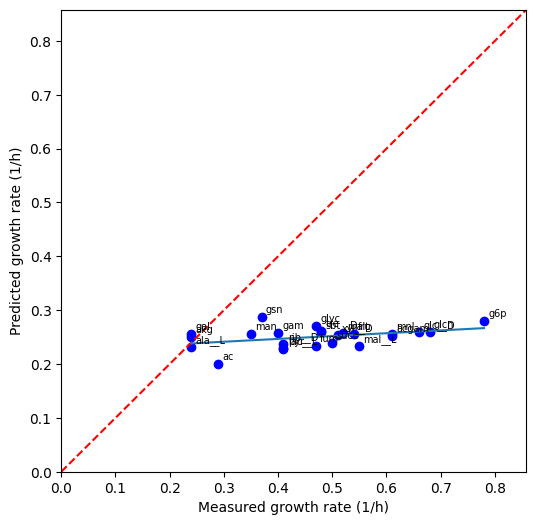

In [12]:
# Scatter plot: measured vs predicted growth rate (red dashed: y=x, blue: linear fit)
from ccfbapy import genFuns
genFuns.scatterPlot(msrd,bmv,xlbl='Measured growth rate (1/h)',ylbl='Predicted growth rate (1/h)',
                    labels=[cs[3:-2] for cs in CSList])